# Missing Values, Outliers, and Data Quality

> Find data quality problems and handle them without hiding important signals.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Quantify missingness before choosing a treatment.
- Distinguish invalid values from legitimate extreme observations.
- Compare deletion, imputation, and robust summaries.
- Learn why outlier decisions must be based on context, not only a rule.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

raw = load_diabetes(as_frame=True).frame.copy()
raw.loc[raw.sample(frac=.06, random_state=7).index, "bmi"] = np.nan
raw.loc[raw.sample(frac=.02, random_state=8).index, "bp"] = 0  # demonstration of potentially suspicious values
print("Missing count:")
print(raw.isna().sum().sort_values(ascending=False).head())
print("Missing %:")
print((raw.isna().mean()*100).round(1).sort_values(ascending=False).head())

Missing count:
bmi    27
age     0
sex     0
bp      0
s1      0
dtype: int64
Missing %:
bmi    6.1
age    0.0
sex    0.0
bp     0.0
s1     0.0
dtype: float64


## Missing data: the choice depends on why it is missing
- **MCAR:** missingness is unrelated to measured or unmeasured values.
- **MAR:** missingness can be explained by observed variables.
- **MNAR:** missingness relates to the unobserved value itself.

Mean imputation is simple but sensitive to outliers. Median imputation is often more robust for skewed numeric columns. For categorical data, a dedicated “Unknown” category can preserve missingness information. Fit imputers on training data only.

In [2]:
from sklearn.impute import SimpleImputer

sample = pd.DataFrame({"income": [30_000, 35_000, np.nan, 42_000, 500_000], "plan": ["basic", None, "plus", "basic", "premium"]})
mean_income = SimpleImputer(strategy="mean").fit_transform(sample[["income"]]).ravel()
median_income = SimpleImputer(strategy="median").fit_transform(sample[["income"]]).ravel()
mode_plan = SimpleImputer(strategy="most_frequent").fit_transform(sample[["plan"]]).ravel()
print("Mean:", mean_income.round(0))
print("Median:", median_income.round(0))
print("Most frequent category:", mode_plan)

Mean: [ 30000.  35000. 151750.  42000. 500000.]
Median: [ 30000.  35000.  38500.  42000. 500000.]
Most frequent category: ['basic' None 'plus' 'basic' 'premium']


## Outliers: inspect before acting
The IQR rule flags values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`. This is a screening heuristic, not a universal deletion rule. A large transaction could be fraud, a genuine enterprise customer, or a data-entry error.

{'lower': 6.5, 'upper': 26.5, 'flagged': [140]}


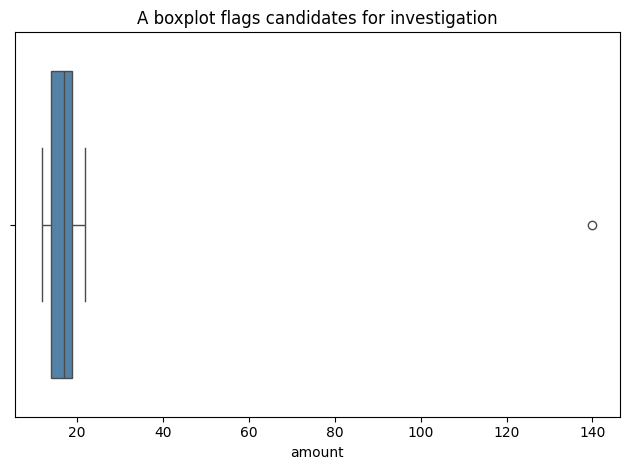

In [3]:
values = pd.Series([12, 13, 14, 15, 17, 18, 19, 22, 140], name="amount")
q1, q3 = values.quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
flags = (values < lower) | (values > upper)
print({"lower": lower, "upper": upper, "flagged": values[flags].tolist()})
sns.boxplot(x=values, color="steelblue")
plt.title("A boxplot flags candidates for investigation")
plt.tight_layout()

## Practice
1. Report missing-value percentages for each column.
2. Compare mean and median for a skewed column.
3. Explain why deleting all flagged outliers can bias a model.

In [4]:
print((sample.isna().mean()*100).round(1))
print("Mean income:", sample["income"].mean(), "Median income:", sample["income"].median())
print("Outliers may be valid observations; validate domain rules and train/test consistency before changing them.")

income    20.0
plan      20.0
dtype: float64
Mean income: 151750.0 Median income: 38500.0
Outliers may be valid observations; validate domain rules and train/test consistency before changing them.
